# SUNSHIELD — Notebook 5: What each change contributes (comparison with the previous method)

Every detector below is scored against the **same ground truth** (Actual 0/1 from the healthy peers,
Notebook 3) and follows the same protocol as Notebook 4: F1 for each k on training → best k → that k on
validation and test. Only one thing changes from one row to the next, so the table shows what each
change brings.

| Detector (Predicted 0/1) | What it is |
|---|---|
| A. Previous definition on the predicted line | change from the previous reading of the LSTM line **alone**, mean ± k·std (the rule used before) |
| B. Residual in kW, mean ± k·std | actual − LSTM, plain mean / std, no smoothing |
| C. Normalised residual, robust σ | (actual − LSTM) / max(LSTM, 20 % capacity), median ± k·σ(MAD), no smoothing, no σ minimum |
| D. C + 1-hour smoothing | EWMA of the residual (Hundman et al., 2018), still no σ minimum |
| **E. Final** | D + σ never below 10 % |
| F. Final rule, LSTM trained on **all** readings | the LSTM also learned the faults (no healthy filter) |
| G. Final rule, physical formula instead of the LSTM | PVWatts-style formula $a\,G\,(1+\gamma(T_m-25))$: is the LSTM worth it? |

A last table checks the **previous ground truth**: how many of the real anomalies it contained at all.

In [1]:
import sys
from pathlib import Path

def find_root():
    candidates = [Path.cwd(), Path.cwd().parent, Path('/content/SUNSHIELD'),
                  Path('/content/drive/MyDrive/SUNSHIELD')]
    for p in candidates:
        if (p / 'sunshield' / 'config.py').exists():
            return p
    if 'google.colab' in sys.modules:
        from google.colab import drive
        drive.mount('/content/drive')
        if (candidates[-1] / 'sunshield' / 'config.py').exists():
            return candidates[-1]
    raise FileNotFoundError('Open this notebook from the SUNSHIELD folder, or put the folder in /content '
                            'or in My Drive on Google Drive.')

ROOT = find_root()
sys.path.insert(0, str(ROOT))

In [2]:
import os, json
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display

from sunshield import config as C, model as M, anomaly as A, evaluate as E, plots as P

P.use_style()
pd.set_option('display.width', 160)
tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel('ERROR')       # hide TensorFlow retracing notices
OUT = C.RESULTS_DIR
df = pd.read_csv(C.OUT_DIR / 'step3' / 'flags.csv', parse_dates=['DATE_TIME'])
df = df.sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)
info = json.load(open(C.OUT_DIR / 'step2' / 'model_info.json'))
W = info['window']

## LSTM trained on all readings (for detector D)
Same network, window and seeds as the final model; the only difference is the target: the mean of
**all** inverters (faults included) instead of the healthy ones.

In [3]:
weather = pd.read_csv(C.OUT_DIR / 'step1' / 'weather.csv', parse_dates=['DATE_TIME'])
readings = pd.read_csv(C.OUT_DIR / 'step1' / 'readings.csv', parse_dates=['DATE_TIME'])
params = json.load(open(C.OUT_DIR / 'step1' / 'params.json'))
CAPACITY = {int(p): v for p, v in params['capacity_kW'].items()}
timeline = M.scaled_timeline(weather, M.fit_feature_scaler(weather))
all_targets = (readings.groupby(['PLANT_ID', 'DATE_TIME', 'SPLIT'])['AC_POWER']
               .agg(TARGET_kW='mean', N_HEALTHY='size').reset_index())
models_all = {}
for plant in C.PLANTS:
    data = M.plant_data(timeline, all_targets, plant, W, CAPACITY[plant])
    models_all[plant] = [M.train_one(data, W, C.SEED + s)[0] for s in range(C.N_SEEDS)]
pred_all = M.predict_readings(models_all, timeline, readings, W, CAPACITY)
key = ['SOURCE_KEY', 'DATE_TIME']
df = df.merge(readings[key].assign(EXPECTED_LSTM_ALL_kW=pred_all.to_numpy()), on=key, how='left')

## Build the Predicted 0/1 of every detector

In [4]:
def flag_with(df, value_col, prefix, **rule):
    out = A.flag_line(df[['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', value_col]], value_col, prefix, **rule)
    return out.loc[df.index, [f'{prefix}_k{k:g}' for k in C.K_VALUES]].to_numpy()

df['RES_KW'] = df['AC_POWER'] - df['EXPECTED_LSTM_kW']
df['DEV_LSTM_ALL'] = A.relative_deviation(df['AC_POWER'], df['EXPECTED_LSTM_ALL_kW'], df['FLOOR_kW'])
df['DEV_PHYS'] = A.relative_deviation(df['AC_POWER'], df['EXPECTED_PHYS_kW'], df['FLOOR_kW'])

detectors = {
    'A. Previous definition on the predicted line': 'A',
    'B. Residual in kW, mean ± k·std': 'B',
    'C. Normalised residual, robust σ': 'C',
    'D. C + 1-hour smoothing': 'D',
    'E. Final (D + σ minimum 10 %)': 'pred',
    'F. Final rule, LSTM trained on all readings': 'F',
    'G. Final rule, physical formula instead of LSTM': 'G',
}
cols = lambda p: [f'{p}_k{k:g}' for k in C.K_VALUES]
for k in C.K_VALUES:                       # A: the old rule, on the LSTM line alone, per inverter
    df[f'A_k{k:g}'] = df.groupby('SOURCE_KEY')['EXPECTED_LSTM_kW'].transform(
        lambda s: A.previous_definition_flags(s.to_numpy(), k))
df[cols('B')] = flag_with(df, 'RES_KW', 'B', robust=False, span=1, sigma_min=0)
df[cols('C')] = flag_with(df, 'DEV_LSTM', 'C', span=1, sigma_min=0)
df[cols('D')] = flag_with(df, 'DEV_LSTM', 'D', sigma_min=0)
df[cols('F')] = flag_with(df, 'DEV_LSTM_ALL', 'F')
df[cols('G')] = flag_with(df, 'DEV_PHYS', 'G')

## Results — same ground truth, best k chosen on training for each detector

In [5]:
rows, sweeps = [], {}
for name, prefix in detectors.items():
    t = E.sweep(df, 'actual', prefix)
    sweeps[name] = t
    bk = E.best_k_from_training(t)
    r = t[t['k'] == bk].set_index('Split')
    rows.append({'Detector': name, 'best k': bk,
                 'Training F1': r.loc['Training', 'F1'], 'Validation F1': r.loc['Validation', 'F1'],
                 'Testing F1': r.loc['Testing', 'F1'], 'Testing precision': r.loc['Testing', 'Precision'],
                 'Testing recall': r.loc['Testing', 'Recall']})
comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / 'comparison_with_previous.csv', index=False)
comparison

,Detector,best k,Training F1,Validation F1,Testing F1,Testing precision,Testing recall
0,A. Previous definition on the predicted line,1.0,0.2198,0.2402,0.2901,0.1997,0.5301
1,"B. Residual in kW, mean ± k·std",1.5,0.5716,0.5891,0.6120,0.6548,0.5744
2,"C. Normalised residual, robust σ",3.0,0.7278,0.7210,0.7529,0.6533,0.8883
3,D. C + 1-hour smoothing,3.0,0.8181,0.7776,0.8243,0.7011,1.0000
4,E. Final (D + σ minimum 10 %),2.5,0.9750,0.9717,0.9689,0.9567,0.9815
5,"F. Final rule, LSTM trained on all readings",3.0,0.6321,0.6601,0.6628,0.5398,0.8583
6,"G. Final rule, physical formula instead of LSTM",2.5,0.9608,0.9641,0.9585,0.9615,0.9556


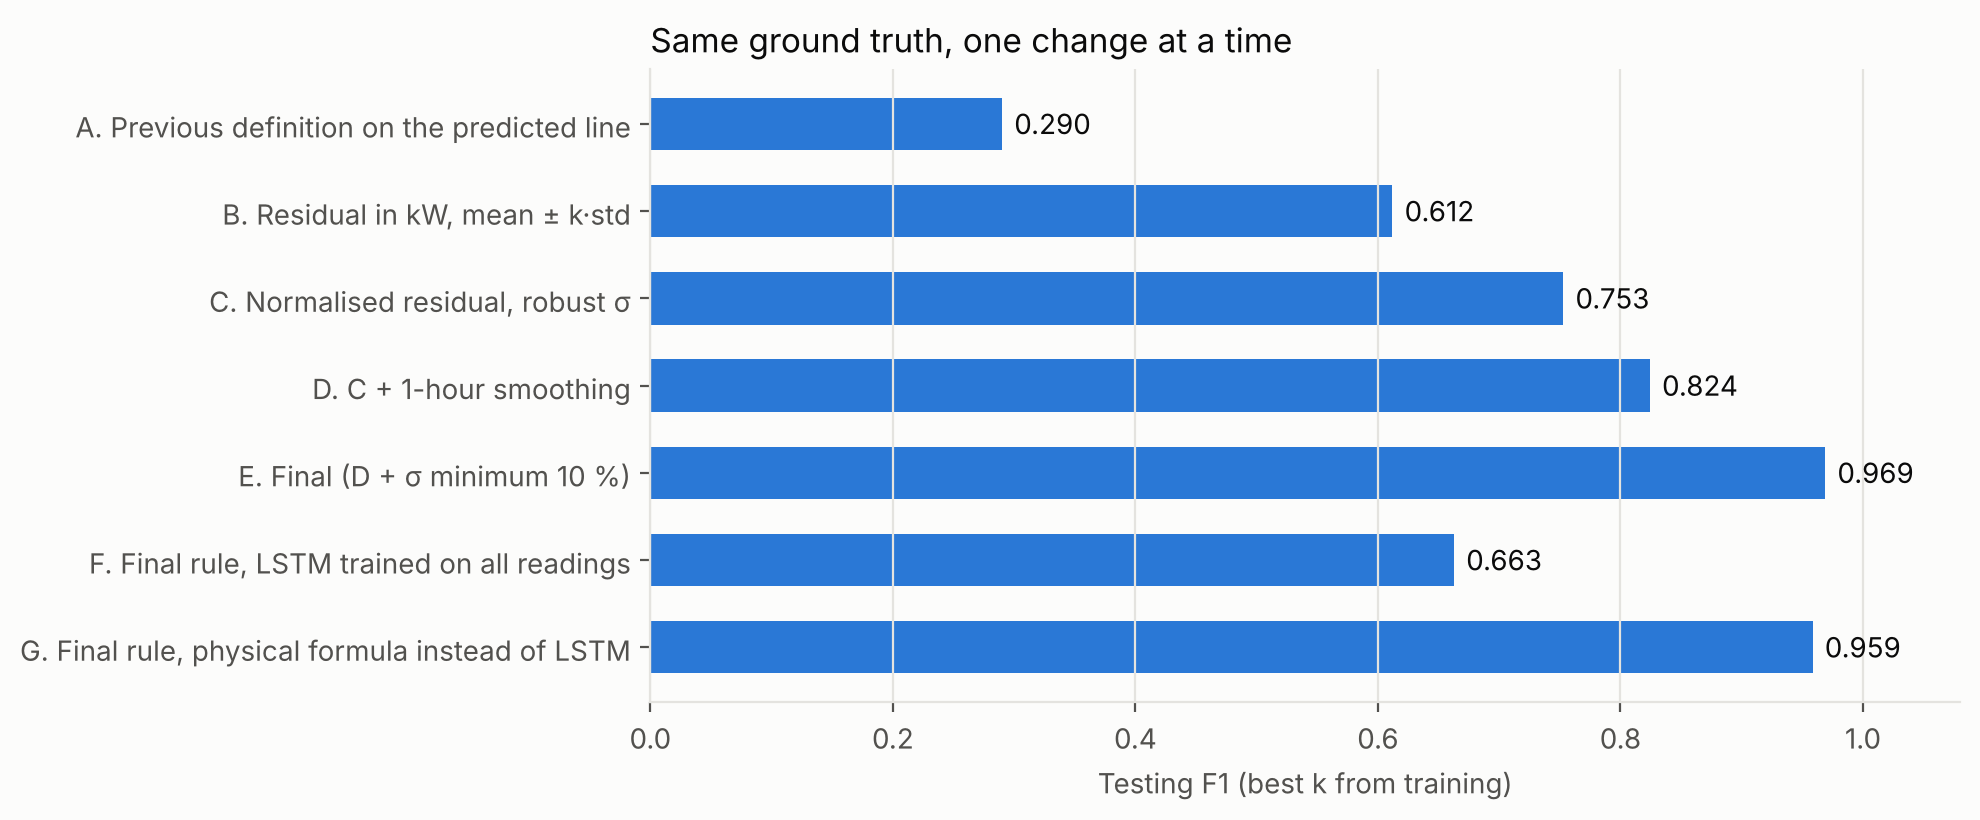

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(comparison))[::-1]
ax.barh(y, comparison['Testing F1'], color=P.BLUE, height=0.6)
for yi, v in zip(y, comparison['Testing F1']):
    ax.text(v + 0.01, yi, f'{v:.3f}', va='center', color=P.INK)
ax.set_yticks(y, comparison['Detector'])
ax.set_xlim(0, 1.08)
ax.set_xlabel('Testing F1 (best k from training)')
ax.set_title('Same ground truth, one change at a time')
ax.grid(axis='y', visible=False)
fig.tight_layout()
fig.savefig(OUT / 'comparison_with_previous.png', dpi=150)
plt.show()

## The previous ground truth
How many of the anomalies of the new ground truth did the previous **Actual 0/1** contain? (Previous rule on
the actual line alone: change from the previous reading, mean ± k·std; same k on both sides.)

In [7]:
for k in C.K_VALUES:
    df[f'OLD_GT_k{k:g}'] = df.groupby('SOURCE_KEY')['AC_POWER'].transform(
        lambda s: A.previous_definition_flags(s.to_numpy(), k))
rows = []
for k in C.K_VALUES:
    new, old = df[f'actual_k{k:g}'] != 0, df[f'OLD_GT_k{k:g}'] != 0
    drop_new = df[f'actual_k{k:g}'] == -1
    outage = drop_new & (df['AC_POWER'] == 0)
    rows.append({'k': k, 'new ground truth: anomalies': int(new.sum()),
                 'also in previous ground truth': int((new & old).sum()),
                 'share': round((new & old).sum() / new.sum(), 3),
                 'outage readings (0 kW, expected > 0)': int(outage.sum()),
                 'outage readings in previous ground truth': int((outage & old).sum())})
old_gt = pd.DataFrame(rows)
old_gt.to_csv(OUT / 'previous_ground_truth_coverage.csv', index=False)
old_gt

,k,new ground truth: anomalies,also in previous ground truth,share,"outage readings (0 kW, expected > 0)",outage readings in previous ground truth
0,1.0,8363,2839,0.339,3834,453
1,1.5,6548,1750,0.267,3825,376
2,2.0,5851,1268,0.217,3820,323
3,2.5,5441,889,0.163,3800,276
4,3.0,5109,611,0.120,3779,242


## Sensitivity of the two settings of the definition (training and validation only)
The smoothing span and the σ minimum were chosen from training and validation results only (never from the
test days). This table shows how the result moves when they change. A larger σ minimum always makes the two lines agree more, because it keeps only
the largest anomalies. That is why it is **not** chosen by F1 (15 % scores higher). It is set at 10 % as a
tolerance, and the last column shows what a larger value would cost: big losses that drop out of the ground truth.

In [8]:
big = (df['AC_POWER'] < 0.5 * df['EXPECTED_PEER_kW']) & (df['EXPECTED_PEER_kW'] > 0.1 * df['CAPACITY_kW'])
rows = []
for span in [1, 2, 4, 6]:
    for smin in [0.05, 0.075, 0.10, 0.125, 0.15]:
        t = df[['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', 'SPLIT']].copy()
        t[cols('a')] = flag_with(df, 'DEV_PEER', 'a', span=span, sigma_min=smin)
        t[cols('p')] = flag_with(df, 'DEV_LSTM', 'p', span=span, sigma_min=smin)
        tab = E.sweep(t, 'a', 'p')
        bk = E.best_k_from_training(tab)
        r = tab[tab['k'] == bk].set_index('Split')
        rows.append({'EWMA span (readings)': span, 'σ minimum': smin, 'best k': bk,
                     'Training F1': r.loc['Training', 'F1'], 'Validation F1': r.loc['Validation', 'F1'],
                     'ground truth: share of big losses kept': round((big & (t[f'a_k{bk:g}'] != 0)).sum() / big.sum(), 3)})
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(OUT / 'sensitivity_span_sigma_min.csv', index=False)
sensitivity.pivot(index='EWMA span (readings)', columns='σ minimum', values='Validation F1')

σ minimum,0.050,0.075,0.100,0.125,0.150
EWMA span (readings),,,,,
1,0.8119,0.8956,0.9327,0.9414,0.9655
2,0.8676,0.9249,0.9545,0.9738,0.9658
4,0.9343,0.9651,0.9717,0.9453,0.9636
6,0.9410,0.9524,0.9414,0.9676,0.9671


In [9]:
sensitivity

,EWMA span (readings),σ minimum,best k,Training F1,Validation F1,ground truth: share of big losses kept
0,1,0.050,3.0,0.8152,0.8119,0.989
1,1,0.075,3.0,0.8920,0.8956,0.989
2,1,0.100,3.0,0.9425,0.9327,0.989
3,1,0.125,3.0,0.9698,0.9414,0.988
4,1,0.150,3.0,0.9823,0.9655,0.987
5,2,0.050,3.0,0.8702,0.8676,0.986
6,2,0.075,3.0,0.9455,0.9249,0.986
7,2,0.100,3.0,0.9715,0.9545,0.986
8,2,0.125,3.0,0.9789,0.9738,0.981
9,2,0.150,3.0,0.9870,0.9658,0.964
